# Financial Risk Management using Machine Learning on z/OS

This notebook converts the IBM Developer Journey *Financial Risk Management using Machine Learning on z/OS* into a Jupyter notebook. It covers the same three parts as the original README:

- **Part A:** discover and test the Financial Risk Management API
- **Part B:** build a financial application (the original is HTML/CSS/JavaScript; the logic is ported here to Python)
- **Part C:** extend the application in the cloud

It also summarises the machine learning workflow behind the score.

> **Security:** the notebook never stores your client ID or secret. Set them as environment variables (`IBM_CLIENT_ID`, `IBM_CLIENT_SECRET`) before running Part A.

## Architecture

MPLbank is a fictitious retail bank. Its loan decisions are scored by a model built and deployed with IBM Machine Learning for z/OS. An API layer in IBM Cloud exposes the score to applications.

![Architecture](attachment:mlz_architecture_mplbank.png)

### Components

- Db2 for z/OS
- Machine Learning for z/OS
- API Connect
- Secure Gateway Service
- DataPower Gateway

## Machine learning workflow

The predictive model uses four customer attributes: **age**, **number of credit cards**, **income** and **number of car loans**. It predicts a score (the probability that the customer can repay a loan). Historical data is split **80% for training and 20% for evaluation**, so the model is tested on data it has not seen.

![Workflow](attachment:mlz_workflow.png)

## Part A: Discover and test the Financial Risk Management API

### A.1 Create an application and get your credentials

1. Sign up for an IBM ID and go to the **API Developer Portal**.
2. Create an account and activate it from the email you receive.
3. Go to **Apps**, click **Create new App**, and note the **client ID** and **client secret**.

### A.2 Subscribe to the Banking product

In the portal, open **API Products**, choose **Banking Product**, click **Subscribe** on the Default Plan, and select the app you created.

### A.3 Operation: `GET /customers/loan/calculateScore`

| Parameter | Type | Example |
|---|---|---|
| `age` | integer | 23 |
| `income` | integer | 30000 |
| `numberOfCard` | integer | 2 |
| `numberOfCarLoan` | integer | 1 |

All available customer IDs are listed in `identifier/customerIDs.txt` in the original repository.

In [ ]:
import os, json
import requests

# The endpoint used by the original financialAPI.js
API_BASE = "https://api.us.apiconnect.ibmcloud.com/spbodieusibmcom-prod/developer-contest/mplbank"
SCORE_PATH = "/customers/loan/calculateScore"

# Credentials come from the environment, never from the notebook
IBM_CLIENT_ID = os.environ.get("IBM_CLIENT_ID", "")
IBM_CLIENT_SECRET = os.environ.get("IBM_CLIENT_SECRET", "")

print("Client ID set:", bool(IBM_CLIENT_ID), "| Client secret set:", bool(IBM_CLIENT_SECRET))

In [ ]:
def build_score_request(age, income, number_of_card, number_of_car_loan):
    """Port of loanApproval() in financialAPI.js: returns the full URL and query string."""
    for name, value in [("age", age), ("income", income),
                        ("numberOfCard", number_of_card), ("numberOfCarLoan", number_of_car_loan)]:
        if not isinstance(value, int) or value < 0:
            raise ValueError(f"{name} must be a non-negative integer, got {value!r}")
    params = {"age": age, "income": income,
              "numberOfCard": number_of_card, "numberOfCarLoan": number_of_car_loan}
    return API_BASE + SCORE_PATH, params

def call_score_api(age, income, number_of_card, number_of_car_loan, timeout=15):
    """Port of doGet(): sends the GET request with the client headers."""
    url, params = build_score_request(age, income, number_of_card, number_of_car_loan)
    headers = {"x-ibm-client-id": IBM_CLIENT_ID,
               "x-ibm-client-secret": IBM_CLIENT_SECRET,
               "Content-Type": "application/json"}
    resp = requests.get(url, params=params, headers=headers, timeout=timeout)
    # Pretty-print like JSON.stringify(data, null, 4) in the original app
    try:
        return resp.status_code, json.dumps(resp.json(), indent=4)
    except ValueError:
        return resp.status_code, resp.text

In [ ]:
# Run the example from the README: age 23, income 30000, 2 cards, 1 car loan
if not (IBM_CLIENT_ID and IBM_CLIENT_SECRET):
    print("Set IBM_CLIENT_ID and IBM_CLIENT_SECRET to call the live API.")
else:
    try:
        status, body = call_score_api(23, 30000, 2, 1)
        print("HTTP status:", status)
        print(body)
    except requests.RequestException as e:
        print("Could not reach the API from this environment:", e)

### A.4 Check the request without calling the API

The next cell builds the request for several customers and shows the URL and query string. It makes no network call, so it runs anywhere.

In [ ]:
import pandas as pd

examples = [
    (23, 30000, 2, 1),
    (45, 60000, 1, 0),
    (31, 18000, 3, 2),
]
rows = []
for age, income, cards, loans in examples:
    url, params = build_score_request(age, income, cards, loans)
    query = "&".join(f"{k}={v}" for k, v in params.items())
    rows.append({"age": age, "income": income, "numberOfCard": cards,
                 "numberOfCarLoan": loans, "request": f"{url}?{query}"})
pd.DataFrame(rows)

---

:thumbsup: **Part A complete:** you can discover and test the API. Continue to Part B.

## Part B: Build a financial application

The original application is a small web page (`index.html`) with four inputs and a **Go** button. The button runs `loanApproval()` in `financialAPI.js`, which calls the API and shows the JSON result. The notebook reproduces that logic in Python. The HTML front end is not needed to test the API.

![Financial application](attachment:financial_application.png)

### B.1 Mapping from the original JavaScript

| Original (`financialAPI.js`) | Notebook (Python) |
|---|---|
| `url_api_devloper_portal` | `API_BASE` |
| `IBM_CLIENT_ID`, `IBM_CLIENT_SECRET` | environment variables |
| `loanApproval()` | `build_score_request()` |
| `doGet()` | `call_score_api()` |
| `JSON.stringify(data, null, 4)` | `json.dumps(..., indent=4)` |

### B.2 Expected output

A successful call returns a score and a message, for example:

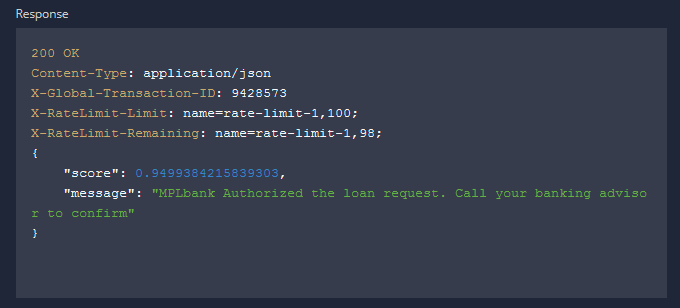

## Part C: Extend the application in the cloud

The original journey deploys the web application to IBM Cloud with the Node.js SDK:

1. Sign in to IBM Cloud and create a **SDK for Node.js** runtime (free for 30 days).
2. Clone the `get-started-node` project from GitHub.
3. Copy the `js` and `css` folders and `index.html` into `views/`, and remove the default stylesheets.
4. Edit `manifest.yml` to set the app name, and remove the random route line.
5. Deploy with `bx login` and `bx app push`, then open **Visit App URL**.

The notebook does not deploy anything. These steps are kept here for reference.

## Optional: a machine learning sketch of the 80/20 workflow

The real scoring model runs on IBM Z and is not included in this repository, so the cell below only shows the workflow on **synthetic** data. The numbers mean nothing financially. It illustrates the 80/20 split and the four input features.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

rng = np.random.default_rng(0)
n = 2000
data = pd.DataFrame({
    "age": rng.integers(18, 75, n),
    "income": rng.integers(10000, 120000, n),
    "numberOfCard": rng.integers(0, 6, n),
    "numberOfCarLoan": rng.integers(0, 4, n),
})
# Synthetic label: higher income and age, fewer loans -> more likely to repay
logit = 0.00004 * data["income"] + 0.02 * data["age"] - 0.4 * data["numberOfCarLoan"] - 0.2 * data["numberOfCard"] - 2.5
y = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)

X_train, X_test, y_train, y_test = train_test_split(data, y, test_size=0.2, random_state=0)
print(f"Training rows: {len(X_train)} (80%), evaluation rows: {len(X_test)} (20%)")

model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
print("Accuracy:", round(accuracy_score(y_test, proba >= 0.5), 3))
print("ROC AUC:", round(roc_auc_score(y_test, proba), 3))

## Extended stack: from model to production

The parts below extend the 80/20 sketch above (it must be run first, since these cells reuse `data`, `y` and `model`). Everything runs on the **synthetic** data, so the numbers are illustrative only.

| Step | Technology |
|---|---|
| D | Data Engineering: validated feature pipeline |
| E | XGBoost model |
| F | TensorFlow / Deep Learning model |
| G | MLOps: model registry, drift check |
| H | Visualization |
| I | Computer Vision: loan document detection |
| J | Flask scoring service |
| K | Bash client script |
| L | C++ scoring engine |
| M | Golang concurrent client |

### D. Data Engineering: validated feature pipeline

In [ ]:
from pathlib import Path
WORK = Path(".")  # flat project: no sub-folders

BASE_FEATURES = ["age", "income", "numberOfCard", "numberOfCarLoan"]
RULES = {"age": (18, 100), "income": (0, 10_000_000),
         "numberOfCard": (0, 50), "numberOfCarLoan": (0, 20)}

def validate(df):
    """Drop rows with nulls or out-of-range values and report how many were removed."""
    before = len(df)
    df = df.dropna(subset=BASE_FEATURES)
    for col, (lo, hi) in RULES.items():
        df = df[df[col].between(lo, hi)]
    print(f"validate: kept {len(df)} of {before} rows")
    return df.reset_index(drop=True)

def add_features(df):
    out = df.copy()
    out["incomePerCard"] = out["income"] / (out["numberOfCard"] + 1)
    out["loanBurden"] = out["numberOfCarLoan"] / (out["numberOfCard"] + out["numberOfCarLoan"] + 1)
    out["incomeLog"] = np.log1p(out["income"])
    return out

ENG_FEATURES = BASE_FEATURES + ["incomePerCard", "loanBurden", "incomeLog"]

raw = data.assign(repaid=y)
clean = add_features(validate(raw))
clean.to_csv(WORK / "customers_features.csv", index=False)

Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    clean[ENG_FEATURES], clean["repaid"], test_size=0.2, random_state=0)
print("Saved", WORK / "customers_features.csv", "| train/test:", len(Xe_train), len(Xe_test))

### E. XGBoost

In [ ]:
results = {"logistic_regression": float(roc_auc_score(y_test, proba))}
try:
    from xgboost import XGBClassifier
    xgb = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                        subsample=0.9, eval_metric="logloss")
    xgb.fit(Xe_train, ye_train)
    xgb_proba = xgb.predict_proba(Xe_test)[:, 1]
    results["xgboost"] = float(roc_auc_score(ye_test, xgb_proba))
    print("XGBoost ROC AUC:", round(results["xgboost"], 3))
except ImportError:
    xgb = None
    print("xgboost is not installed here. Run: pip install xgboost")

### F. TensorFlow / Deep Learning

In [ ]:
try:
    import tensorflow as tf
    mu, sd = Xe_train.mean(), Xe_train.std().replace(0, 1)
    scale = lambda d: ((d - mu) / sd).values.astype("float32")
    tf.keras.utils.set_random_seed(0)
    dl = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(len(ENG_FEATURES),)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    dl.compile(optimizer="adam", loss="binary_crossentropy",
               metrics=[tf.keras.metrics.AUC(name="auc")])
    hist = dl.fit(scale(Xe_train), ye_train.values, validation_split=0.2,
                  epochs=30, batch_size=64, verbose=0)
    dl_proba = dl.predict(scale(Xe_test), verbose=0).ravel()
    results["tensorflow_mlp"] = float(roc_auc_score(ye_test, dl_proba))
    print("TensorFlow MLP ROC AUC:", round(results["tensorflow_mlp"], 3))
except ImportError:
    hist = None
    print("tensorflow is not installed here. Run: pip install tensorflow")

### G. MLOps: registry, metadata and drift check

In [ ]:
import joblib, datetime, hashlib

def register_model(name, version, mdl, metrics, features):
    prefix = f"{name}_v{version}"   # flat: files share a prefix instead of a folder
    joblib.dump(mdl, WORK / f"{prefix}_model.joblib")
    digest = hashlib.sha256((WORK / f"{prefix}_model.joblib").read_bytes()).hexdigest()[:16]
    meta = {"name": name, "version": version, "features": features, "metrics": metrics,
            "trained_at": datetime.datetime.now(datetime.timezone.utc).isoformat(),
            "sha256_16": digest, "data": "synthetic"}
    (WORK / f"{prefix}_metadata.json").write_text(json.dumps(meta, indent=2))
    return prefix

model_dir = register_model("loan_score_lr", 1, model,
                           {"roc_auc": results["logistic_regression"]}, BASE_FEATURES)
print("Registered:", model_dir)

def population_stability_index(expected, actual, bins=10):
    """PSI > 0.2 is a common rule of thumb for significant drift."""
    edges = np.quantile(expected, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

# Simulate a new batch where incomes have shifted upwards
new_batch = X_test["income"] * 1.35
drift = {"income": population_stability_index(X_train["income"], new_batch),
         "age": population_stability_index(X_train["age"], X_test["age"])}
for feat, psi in drift.items():
    print(f"PSI {feat}: {psi:.3f} ->", "DRIFT: retrain" if psi > 0.2 else "stable")

### H. Visualization

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

fpr, tpr, _ = roc_curve(y_test, proba)
axes[0].plot(fpr, tpr, label=f"Logistic (AUC {results['logistic_regression']:.2f})")
if "xgboost" in results:
    f2, t2, _ = roc_curve(ye_test, xgb_proba)
    axes[0].plot(f2, t2, label=f"XGBoost (AUC {results['xgboost']:.2f})")
if "tensorflow_mlp" in results:
    f3, t3, _ = roc_curve(ye_test, dl_proba)
    axes[0].plot(f3, t3, label=f"MLP (AUC {results['tensorflow_mlp']:.2f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend()

axes[1].barh(BASE_FEATURES, model.coef_[0] * X_train.std().values)
axes[1].set(title="Logistic coefficients (standardised)")

axes[2].hist(proba, bins=25, color="#4c72b0")
axes[2].set(title="Predicted repayment score", xlabel="score", ylabel="customers")

plt.tight_layout()
plt.savefig(WORK / "model_overview.png", dpi=120)
plt.show()

### I. Computer Vision: loan document detection

A common step before reading a scanned loan form is to find the page in the photo and straighten it. This cell draws a synthetic, rotated "application form" and uses OpenCV to detect and deskew it. Reading the text itself (OCR) is not included.

In [ ]:
import cv2

# Synthetic photo: a rotated white page on a dark desk
canvas = np.full((600, 800, 3), 40, np.uint8)
page = np.full((420, 300, 3), 245, np.uint8)
cv2.putText(page, "LOAN APPLICATION", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
for i, label in enumerate(["Age: 23", "Income: 30000", "Cards: 2", "Car loans: 1"]):
    cv2.putText(page, label, (20, 100 + 50 * i), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (30, 30, 30), 1)
M = cv2.getRotationMatrix2D((150, 210), 17, 1.0)
M[:, 2] += (250, 90)
cv2.warpAffine(page, M, (800, 600), dst=canvas, borderMode=cv2.BORDER_TRANSPARENT)

def deskew_document(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, mask = cv2.threshold(gray, 150, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    biggest = max(contours, key=cv2.contourArea)
    box = cv2.boxPoints(cv2.minAreaRect(biggest)).astype("float32")
    s = box.sum(1); d = np.diff(box, axis=1).ravel()
    tl, br = box[s.argmin()], box[s.argmax()]
    tr, bl = box[d.argmin()], box[d.argmax()]
    w = int(max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl)))
    h = int(max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr)))
    dst = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], "float32")
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(
        np.array([tl, tr, br, bl], "float32"), dst), (w, h))

flat = deskew_document(canvas)
print("Detected page size:", flat.shape[1], "x", flat.shape[0])
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(canvas[:, :, ::-1]); ax[0].set_title("Input photo"); ax[0].axis("off")
ax[1].imshow(flat[:, :, ::-1]); ax[1].set_title("Detected and deskewed"); ax[1].axis("off")
plt.show()

### J. Flask scoring service

A small API with the same query parameters as the bank API, served by the registered model.

In [ ]:
APP_CODE = '''
import json, sys
from pathlib import Path
import joblib
import pandas as pd
from flask import Flask, jsonify, request

PREFIX = sys.argv[1] if len(sys.argv) > 1 else "loan_score_lr_v1"
model = joblib.load(f"{PREFIX}_model.joblib")
meta = json.loads(Path(f"{PREFIX}_metadata.json").read_text())
FEATURES = meta["features"]

app = Flask(__name__)

@app.get("/health")
def health():
    return jsonify(status="ok", model=meta["name"], version=meta["version"])

@app.get("/score")
def score():
    try:
        values = [int(request.args[f]) for f in FEATURES]
    except (KeyError, ValueError):
        return jsonify(error="integer query parameters required: " + ", ".join(FEATURES)), 400
    if any(v < 0 for v in values):
        return jsonify(error="values must be non-negative"), 400
    p = float(model.predict_proba(pd.DataFrame([values], columns=FEATURES))[0, 1])
    return jsonify(score=round(p, 4), model_version=meta["version"])

if __name__ == "__main__":
    app.run(host="127.0.0.1", port=5000)
'''
(WORK / "app.py").write_text(APP_CODE)

import importlib.util, sys
sys.argv = ["app.py", str(model_dir)]
spec = importlib.util.spec_from_file_location("score_app", WORK / "app.py")
score_app = importlib.util.module_from_spec(spec); spec.loader.exec_module(score_app)

client = score_app.app.test_client()
print(client.get("/health").get_json())
print(client.get("/score?age=23&income=30000&numberOfCard=2&numberOfCarLoan=1").get_json())
print(client.get("/score?age=abc").status_code)

### K. Bash client script

In [ ]:
import subprocess, threading
from werkzeug.serving import make_server

BASH_SCRIPT = '''#!/usr/bin/env bash
# Usage: call_score.sh AGE INCOME CARDS CAR_LOANS [BASE_URL]
set -euo pipefail
if [ "$#" -lt 4 ]; then
  echo "usage: $0 AGE INCOME CARDS CAR_LOANS [BASE_URL]" >&2; exit 2
fi
BASE_URL="${5:-http://127.0.0.1:5000}"
curl --fail --silent --show-error --max-time 10 --get "$BASE_URL/score" \\
  --data-urlencode "age=$1" --data-urlencode "income=$2" \\
  --data-urlencode "numberOfCard=$3" --data-urlencode "numberOfCarLoan=$4"
echo
'''
script = WORK / "call_score.sh"
script.write_text(BASH_SCRIPT); script.chmod(0o755)
print("syntax check:", subprocess.run(["bash", "-n", str(script)]).returncode == 0)

# Start the Flask service in a background thread and call it from Bash
server = make_server("127.0.0.1", 5000, score_app.app)
threading.Thread(target=server.serve_forever, daemon=True).start()
r = subprocess.run([str(script.resolve()), "23", "30000", "2", "1"], capture_output=True, text=True)
print(r.stdout.strip() or r.stderr.strip())

### L. C++ scoring engine

The logistic model's coefficients are exported into a small C++ program, compiled with `g++`, and checked against Python.

In [ ]:
import shutil
coef = ", ".join(repr(float(c)) for c in model.coef_[0])
CPP = f'''#include <cmath>
#include <cstdlib>
#include <iostream>

int main(int argc, char** argv) {{
    if (argc != 5) {{ std::cerr << "usage: score age income cards carloans\\n"; return 2; }}
    const double w[4] = {{{coef}}};
    const double b = {float(model.intercept_[0])!r};
    double z = b;
    for (int i = 0; i < 4; ++i) z += w[i] * std::atof(argv[i + 1]);
    std::cout << 1.0 / (1.0 + std::exp(-z)) << "\\n";
    return 0;
}}
'''
cpp_file = WORK / "score.cpp"
cpp_file.write_text(CPP)

if shutil.which("g++"):
    exe = WORK / "score_cpp"
    subprocess.run(["g++", "-O2", "-std=c++17", str(cpp_file), "-o", str(exe)], check=True)
    out = subprocess.run([str(exe.resolve()), "23", "30000", "2", "1"], capture_output=True, text=True).stdout
    py = model.predict_proba(pd.DataFrame([[23, 30000, 2, 1]], columns=BASE_FEATURES))[0, 1]
    print("C++   :", out.strip(), "\nPython:", round(float(py), 6))
else:
    print("g++ not found; source written to", cpp_file)

### M. Golang concurrent client

In [ ]:
GO_CODE = '''package main

import (
	"fmt"
	"io"
	"net/http"
	"net/url"
	"sync"
	"time"
)

func score(client *http.Client, base string, age, income, cards, loans int) (string, error) {
	q := url.Values{}
	q.Set("age", fmt.Sprint(age))
	q.Set("income", fmt.Sprint(income))
	q.Set("numberOfCard", fmt.Sprint(cards))
	q.Set("numberOfCarLoan", fmt.Sprint(loans))
	resp, err := client.Get(base + "/score?" + q.Encode())
	if err != nil {
		return "", err
	}
	defer resp.Body.Close()
	body, err := io.ReadAll(resp.Body)
	return string(body), err
}

func main() {
	client := &http.Client{Timeout: 10 * time.Second}
	customers := [][4]int{{23, 30000, 2, 1}, {45, 60000, 1, 0}, {31, 18000, 3, 2}}
	var wg sync.WaitGroup
	for _, c := range customers {
		wg.Add(1)
		go func(c [4]int) {
			defer wg.Done()
			out, err := score(client, "http://127.0.0.1:5000", c[0], c[1], c[2], c[3])
			if err != nil {
				fmt.Println("error:", err)
				return
			}
			fmt.Printf("%v -> %s", c, out)
		}(c)
	}
	wg.Wait()
}
'''
(WORK / "main.go").write_text(GO_CODE)

if shutil.which("go"):
    r = subprocess.run(["go", "run", "main.go"], cwd=WORK / "go", capture_output=True, text=True)
    print(r.stdout or r.stderr)
else:
    print("Go is not installed here; source written to", WORK / "main.go",
          "\nRun it with: go run main.go")

server.shutdown()   # stop the background Flask service

## Visual output gallery

Outputs for every input (`age`, `income`, `numberOfCard`, `numberOfCarLoan`) and every model, as comparison tables, 2D charts and graphs, 3D graphs, 3D charts and a 3D diagram. Run the earlier cells first. Figures are also saved in `financial_risk_project/figures/`.

An interactive 3D version of these charts is in `interactive_3d.html` (open it in a browser; it needs internet to load plotly.js).

### N.1 Comparison tables

In [ ]:
# VIS
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, brier_score_loss,
                             confusion_matrix, precision_recall_curve, average_precision_score)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

def show(name):
    plt.tight_layout()
    plt.savefig(WORK / f"{name}.png", dpi=110, bbox_inches="tight")
    plt.show()

def table_image(df, title, name, col_width=1.6):
    fig, ax = plt.subplots(figsize=(max(6, col_width * (len(df.columns) + 1)), 0.5 * (len(df) + 2)))
    ax.axis("off"); ax.set_title(title, fontweight="bold", pad=12)
    t = ax.table(cellText=df.round(3).astype(str).values, colLabels=list(df.columns),
                 rowLabels=list(df.index), loc="center", cellLoc="center")
    t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 1.4)
    for (r, c), cell in t.get_celld().items():
        if r == 0: cell.set_facecolor("#4c72b0"); cell.set_text_props(color="white", weight="bold")
    show(name)

# Models on the 4 input features (same rows as the earlier 80/20 split)
assert (ye_test.values == y_test).all()
rf = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=0).fit(X_train, y_train)
hgb = HistGradientBoostingClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
scores = {"Logistic Regression": proba,
          "Random Forest": rf.predict_proba(X_test)[:, 1],
          "Hist. Gradient Boosting": hgb.predict_proba(X_test)[:, 1]}
if xgb is not None: scores["XGBoost"] = xgb_proba
if hist is not None: scores["TensorFlow MLP"] = dl_proba

rows = {}
for name, p in scores.items():
    pred = p >= 0.5
    rows[name] = {"ROC AUC": roc_auc_score(y_test, p), "Accuracy": accuracy_score(y_test, pred),
                  "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                  "F1": f1_score(y_test, pred), "Brier": brier_score_loss(y_test, p)}
metrics = pd.DataFrame(rows).T
print(metrics.round(3).to_string())
table_image(metrics, "Table 1: Model comparison", "table_models")

summary = data.assign(repaid=y).groupby("repaid")[BASE_FEATURES].agg(["mean", "median", "std"])
summary.columns = [f"{a} {b}" for a, b in summary.columns]
summary.index = ["Not repaid (0)", "Repaid (1)"]
table_image(summary.T.rename(columns=str), "Table 2: Each input by outcome", "table_inputs", 2.2)

customers = pd.DataFrame([(23, 30000, 2, 1), (45, 60000, 1, 0), (31, 18000, 3, 2), (60, 95000, 0, 0)],
                         columns=BASE_FEATURES, index=["A", "B", "C", "D"])
cust = pd.DataFrame({n: m.predict_proba(customers)[:, 1] for n, m in
                     [("Logistic", model), ("RandomForest", rf), ("HistGB", hgb)]}, index=customers.index)
table_image(customers.join(cust), "Table 3: Scores for sample customers", "table_customers", 1.5)

### N.2 Charts for each input

In [ ]:
# VIS
labels = {"age": "Age", "income": "Income", "numberOfCard": "Credit cards", "numberOfCarLoan": "Car loans"}
d = data.assign(repaid=y)

# Histograms and density per outcome
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, f in zip(axes.ravel(), BASE_FEATURES):
    ax.hist([d[d.repaid == 0][f], d[d.repaid == 1][f]], bins=15, stacked=True,
            color=["#c44e52", "#55a868"], label=["Not repaid", "Repaid"])
    ax.set(title=f"Histogram: {labels[f]}", xlabel=labels[f], ylabel="customers"); ax.legend()
show("inputs_histograms")

# Box plots and violin plots
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for j, f in enumerate(BASE_FEATURES):
    g = [d[d.repaid == 0][f], d[d.repaid == 1][f]]
    axes[0, j].boxplot(g, tick_labels=["Not repaid", "Repaid"], patch_artist=True,
                       boxprops=dict(facecolor="#8fb4d9")); axes[0, j].set_title(f"Box: {labels[f]}")
    vp = axes[1, j].violinplot(g, showmedians=True)
    axes[1, j].set_xticks([1, 2], ["Not repaid", "Repaid"]); axes[1, j].set_title(f"Violin: {labels[f]}")
show("inputs_box_violin")

# Repayment rate per input: bar, line, area, lollipop
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, f, kind in zip(axes.ravel(), BASE_FEATURES, ["bar", "line", "area", "lollipop"]):
    b = pd.qcut(d[f], 8, duplicates="drop") if d[f].nunique() > 8 else d[f]
    r = d.groupby(b, observed=True)["repaid"].mean(); xs = np.arange(len(r)); lab = [str(i) for i in r.index]
    if kind == "bar": ax.bar(xs, r.values, color="#4c72b0")
    elif kind == "line": ax.plot(xs, r.values, marker="o", color="#dd8452")
    elif kind == "area": ax.fill_between(xs, r.values, alpha=0.5, color="#55a868"); ax.plot(xs, r.values, color="#55a868")
    else: ax.vlines(xs, 0, r.values, color="#8172b3"); ax.plot(xs, r.values, "o", color="#8172b3")
    ax.set_xticks(xs, lab, rotation=45, ha="right", fontsize=7)
    ax.set(title=f"Repayment rate ({kind}): {labels[f]}", ylabel="share repaid", ylim=(0, 1))
show("inputs_repayment_rate")

# Pie, donut, stacked bar, bubble, hexbin, 2D density
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes[0, 0].pie(d["numberOfCard"].value_counts().sort_index(), labels=sorted(d["numberOfCard"].unique()),
               autopct="%1.0f%%"); axes[0, 0].set_title("Pie: credit cards")
w, _ = axes[0, 1].pie(d["numberOfCarLoan"].value_counts().sort_index(), labels=sorted(d["numberOfCarLoan"].unique()),
                      wedgeprops=dict(width=0.4)); axes[0, 1].set_title("Donut: car loans")
ct = pd.crosstab(d["numberOfCard"], d["repaid"])
ct.plot(kind="bar", stacked=True, ax=axes[0, 2], color=["#c44e52", "#55a868"]); axes[0, 2].set_title("Stacked bar: cards by outcome")
g = d.groupby(["numberOfCard", "numberOfCarLoan"]).agg(n=("repaid", "size"), rate=("repaid", "mean")).reset_index()
sc = axes[1, 0].scatter(g.numberOfCard, g.numberOfCarLoan, s=g.n / 1.5, c=g.rate, cmap="RdYlGn", alpha=0.8, edgecolor="k")
plt.colorbar(sc, ax=axes[1, 0], label="repay rate"); axes[1, 0].set(title="Bubble: cards x car loans", xlabel="cards", ylabel="car loans")
hb = axes[1, 1].hexbin(d.age, d.income, gridsize=18, cmap="viridis"); plt.colorbar(hb, ax=axes[1, 1], label="customers")
axes[1, 1].set(title="Hexbin: age vs income", xlabel="age", ylabel="income")
axes[1, 2].scatter(d.age, d.income, c=d.repaid, cmap="RdYlGn", s=8, alpha=0.6)
axes[1, 2].set(title="Scatter: age vs income (colour = outcome)", xlabel="age", ylabel="income")
show("inputs_pie_bubble_hexbin")

# Correlation heatmap and scatter matrix
fig, ax = plt.subplots(figsize=(6, 5))
corr = d.corr(); im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); ax.set_title("Heatmap: correlations"); ax.grid(False); show("inputs_correlation")
pd.plotting.scatter_matrix(d[BASE_FEATURES], figsize=(8, 8), alpha=0.3, diagonal="hist", c=d.repaid.map({0: "#c44e52", 1: "#55a868"}))
plt.suptitle("Scatter matrix of the four inputs"); show("inputs_scatter_matrix")

### N.3 Charts for each model

In [ ]:
# VIS
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for n, p in scores.items():
    f, t, _ = roc_curve(y_test, p); axes[0, 0].plot(f, t, label=f"{n} ({roc_auc_score(y_test, p):.2f})")
    pr, rc, _ = precision_recall_curve(y_test, p); axes[0, 1].plot(rc, pr, label=f"{n} ({average_precision_score(y_test, p):.2f})")
    fp, mp = calibration_curve(y_test, p, n_bins=8); axes[0, 2].plot(mp, fp, marker="o", label=n)
    order = np.argsort(-p); gain = np.cumsum(np.asarray(y_test)[order]) / np.sum(y_test)
    axes[1, 0].plot(np.arange(1, len(p) + 1) / len(p), gain, label=n)
axes[0, 0].plot([0, 1], [0, 1], "--", c="gray"); axes[0, 0].set(title="ROC curves", xlabel="FPR", ylabel="TPR"); axes[0, 0].legend(fontsize=7)
axes[0, 1].set(title="Precision-recall curves", xlabel="recall", ylabel="precision"); axes[0, 1].legend(fontsize=7)
axes[0, 2].plot([0, 1], [0, 1], "--", c="gray"); axes[0, 2].set(title="Calibration", xlabel="predicted", ylabel="observed"); axes[0, 2].legend(fontsize=7)
axes[1, 0].plot([0, 1], [0, 1], "--", c="gray"); axes[1, 0].set(title="Cumulative gains", xlabel="share of customers", ylabel="share of repayers found"); axes[1, 0].legend(fontsize=7)
cm = confusion_matrix(y_test, proba >= 0.5); axes[1, 1].imshow(cm, cmap="Blues"); axes[1, 1].grid(False)
for (i, j), v in np.ndenumerate(cm): axes[1, 1].text(j, i, v, ha="center", va="center", fontsize=14)
axes[1, 1].set_xticks([0, 1], ["pred 0", "pred 1"]); axes[1, 1].set_yticks([0, 1], ["true 0", "true 1"]); axes[1, 1].set_title("Confusion matrix (Logistic)")
pi = permutation_importance(model, X_test, y_test, n_repeats=15, random_state=0, scoring="roc_auc")
axes[1, 2].barh(BASE_FEATURES, pi.importances_mean, xerr=pi.importances_std, color="#8172b3")
axes[1, 2].set_title("Permutation importance (AUC drop)")
show("models_evaluation")

# Radar chart of model metrics
cols = ["ROC AUC", "Accuracy", "Precision", "Recall", "F1"]
ang = np.linspace(0, 2 * np.pi, len(cols), endpoint=False).tolist(); ang += ang[:1]
fig = plt.figure(figsize=(6.5, 6)); ax = fig.add_subplot(111, polar=True)
for n, r in metrics[cols].iterrows():
    v = r.tolist() + r.tolist()[:1]; ax.plot(ang, v, label=n); ax.fill(ang, v, alpha=0.08)
ax.set_xticks(ang[:-1], cols); ax.set_title("Radar: model metrics"); ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=8)
show("models_radar")

# Grouped bar of metrics
metrics[cols].plot(kind="bar", figsize=(10, 4.5), width=0.8); plt.xticks(rotation=20, ha="right")
plt.title("Grouped bar: model metrics"); plt.ylim(0, 1); show("models_grouped_bar")

# Registry-style view: C++, Python and Flask agree
py_s = model.predict_proba(customers)[:, 1]
cpp_s = [float(subprocess.run([str((WORK / "score_cpp").resolve()), *map(str, r)], capture_output=True, text=True).stdout)
         for r in customers.values] if (WORK / "score_cpp").exists() else py_s
flask_s = [score_app.app.test_client().get("/score", query_string=dict(zip(BASE_FEATURES, map(int, r)))).get_json()["score"]
           for r in customers.values]
agree = pd.DataFrame({"Python": py_s, "C++": cpp_s, "Flask": flask_s}, index=customers.index)
agree.plot(kind="bar", figsize=(8, 4)); plt.title("Python vs C++ vs Flask scores"); plt.ylabel("score"); show("service_agreement")
table_image(agree, "Table 4: Same score from every runtime", "table_runtimes", 1.6)

### N.4 3D graphs and 3D charts

In [ ]:
# VIS
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# 3D surface: score vs age and income for different loan counts
A, I = np.meshgrid(np.linspace(18, 75, 40), np.linspace(10000, 120000, 40))
fig = plt.figure(figsize=(15, 5))
for k, loans in enumerate([0, 1, 3]):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    grid = pd.DataFrame({"age": A.ravel(), "income": I.ravel(), "numberOfCard": 2, "numberOfCarLoan": loans})
    Z = model.predict_proba(grid)[:, 1].reshape(A.shape)
    s = ax.plot_surface(A, I, Z, cmap="viridis", edgecolor="none", alpha=0.95)
    ax.set(title=f"3D surface: {loans} car loans", xlabel="age", ylabel="income", zlabel="score"); ax.view_init(25, -60)
show("3d_surface")

# 3D wireframe + contour
fig = plt.figure(figsize=(11, 5))
ax = fig.add_subplot(121, projection="3d")
Z = model.predict_proba(pd.DataFrame({"age": A.ravel(), "income": I.ravel(), "numberOfCard": 2, "numberOfCarLoan": 1}))[:, 1].reshape(A.shape)
ax.plot_wireframe(A, I, Z, rstride=3, cstride=3, color="#4c72b0"); ax.contour(A, I, Z, zdir="z", offset=0, cmap="viridis")
ax.set(title="3D wireframe with floor contour", xlabel="age", ylabel="income", zlabel="score")
ax2 = fig.add_subplot(122); cs = ax2.contourf(A, I, Z, 15, cmap="viridis"); plt.colorbar(cs, ax=ax2)
ax2.set(title="2D contour of the same surface", xlabel="age", ylabel="income")
show("3d_wireframe_contour")

# 3D scatter of customers
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(121, projection="3d")
sc = ax.scatter(X_test.age, X_test.income, X_test.numberOfCard, c=proba, cmap="RdYlGn", s=20)
plt.colorbar(sc, ax=ax, shrink=0.6, label="score"); ax.set(title="3D scatter: age, income, cards", xlabel="age", ylabel="income", zlabel="cards")
ax = fig.add_subplot(122, projection="3d")
ax.scatter(X_test.age, X_test.income, X_test.numberOfCarLoan, c=np.asarray(y_test), cmap="RdYlGn", s=20)
ax.set(title="3D scatter: age, income, car loans (colour = outcome)", xlabel="age", ylabel="income", zlabel="car loans")
show("3d_scatter")

# 3D bar charts
rate = d.pivot_table(index="numberOfCard", columns="numberOfCarLoan", values="repaid", aggfunc="mean")
cnt = d.pivot_table(index="numberOfCard", columns="numberOfCarLoan", values="repaid", aggfunc="size")
fig = plt.figure(figsize=(13, 5.5))
for k, (tab, ttl, cmap) in enumerate([(rate, "3D bar: repayment rate", "RdYlGn"), (cnt, "3D bar: number of customers", "Blues")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    xx, yy = np.meshgrid(tab.index, tab.columns, indexing="ij"); z = tab.values.ravel()
    cols_ = plt.get_cmap(cmap)((z - z.min()) / (np.ptp(z) + 1e-9) * 0.8 + 0.2)
    ax.bar3d(xx.ravel() - 0.35, yy.ravel() - 0.35, 0, 0.7, 0.7, z, color=cols_, shade=True)
    ax.set(title=ttl, xlabel="cards", ylabel="car loans"); ax.view_init(28, -55)
show("3d_bars")

# 3D histogram of age vs income
H, xe, ye_ = np.histogram2d(d.age, d.income, bins=[8, 8])
xp, yp = np.meshgrid(xe[:-1], ye_[:-1], indexing="ij")
fig = plt.figure(figsize=(7, 6)); ax = fig.add_subplot(111, projection="3d")
ax.bar3d(xp.ravel(), yp.ravel(), 0, np.diff(xe)[0] * 0.9, np.diff(ye_)[0] * 0.9, H.ravel(), color=plt.cm.plasma(H.ravel() / H.max()))
ax.set(title="3D histogram: age x income", xlabel="age", ylabel="income", zlabel="customers"); show("3d_histogram")

# 3D line plot: score vs income for each loan count
fig = plt.figure(figsize=(8, 6)); ax = fig.add_subplot(111, projection="3d")
inc = np.linspace(10000, 120000, 60)
for loans in range(4):
    z = model.predict_proba(pd.DataFrame({"age": 40, "income": inc, "numberOfCard": 2, "numberOfCarLoan": loans}))[:, 1]
    ax.plot(inc, np.full_like(inc, loans), z, lw=2, label=f"{loans} loans")
ax.set(title="3D lines: score vs income by car loans", xlabel="income", ylabel="car loans", zlabel="score"); ax.legend(); show("3d_lines")

### N.5 3D diagram of the whole system

In [ ]:
# VIS
from matplotlib.patches import Polygon
c30, s30 = np.cos(np.pi / 6), np.sin(np.pi / 6)
def iso(x, y, z): return (x - y) * c30, (x + y) * s30 + z

def iso_box(ax, x, y, z, dx, dy, dz, color):
    """Draw a cuboid in isometric projection (top, left and right faces shaded)."""
    faces = [([(x, y, z + dz), (x + dx, y, z + dz), (x + dx, y + dy, z + dz), (x, y + dy, z + dz)], 1.0),
             ([(x, y, z), (x + dx, y, z), (x + dx, y, z + dz), (x, y, z + dz)], 0.8),
             ([(x + dx, y, z), (x + dx, y + dy, z), (x + dx, y + dy, z + dz), (x + dx, y, z + dz)], 0.6)]
    for pts, shade in faces:
        ax.add_patch(Polygon([iso(*p) for p in pts], closed=True, edgecolor="k", lw=0.8,
                             facecolor=np.clip(np.array(matplotlib.colors.to_rgb(color)) * shade, 0, 1)))

import matplotlib
layers = [("Data", ["Db2 / CSV", "Validation", "Features"], "#6baed6"),
          ("Models", ["Logistic", "XGBoost", "TensorFlow"], "#74c476"),
          ("MLOps", ["Registry", "Metadata", "Drift (PSI)"], "#fd8d3c"),
          ("Serving", ["Flask", "C++", "Golang / Bash"], "#9e9ac8"),
          ("Insight", ["Charts", "3D plots", "Computer Vision"], "#fb6a4a")]
fig, ax = plt.subplots(figsize=(10, 9)); ax.set_aspect("equal"); ax.axis("off"); ax.grid(False)
GAP = 2.4
for z, (name, boxes, col) in enumerate(layers):
    z0 = z * GAP
    iso_box(ax, 0, 0, z0, 3.6, 1.4, 0.15, col)                     # slab
    for i in reversed(range(len(boxes))):                             # blocks, back to front
        iso_box(ax, 0.1 + i * 1.15, 0.2, z0 + 0.15, 1.0, 1.0, 0.7, col)
    for i, b in enumerate(boxes):
        tx, ty = iso(0.1 + i * 1.15 + 0.5, 0.7, z0 + 0.85)
        ax.text(tx, ty, b, ha="center", va="center", fontsize=7.5, fontweight="bold")
    lx, ly = iso(0, 1.4, z0 + 0.1)
    ax.text(lx - 0.3, ly, name, ha="right", va="center", fontsize=13, fontweight="bold")
    if z < len(layers) - 1:
        a0 = iso(4.6, 0.0, z0 + 0.1); a1 = iso(4.6, 0.0, z0 + GAP + 0.1)
        ax.annotate("", xy=a1, xytext=a0, arrowprops=dict(arrowstyle="-|>", lw=2, color="k"))
ax.autoscale_view(); ax.set_title("3D isometric system diagram: from data to insight", fontsize=13)
show("3d_system_diagram")

### Pre-rendered figures

These PNG files sit next to the notebook (flat project, no sub-folders).

![table_models](table_models.png)

![table_inputs](table_inputs.png)

![table_customers](table_customers.png)

![table_runtimes](table_runtimes.png)

![inputs_histograms](inputs_histograms.png)

![inputs_box_violin](inputs_box_violin.png)

![inputs_repayment_rate](inputs_repayment_rate.png)

![inputs_pie_bubble_hexbin](inputs_pie_bubble_hexbin.png)

![inputs_correlation](inputs_correlation.png)

![inputs_scatter_matrix](inputs_scatter_matrix.png)

![models_evaluation](models_evaluation.png)

![models_radar](models_radar.png)

![models_grouped_bar](models_grouped_bar.png)

![service_agreement](service_agreement.png)

![3d_surface](3d_surface.png)

![3d_wireframe_contour](3d_wireframe_contour.png)

![3d_scatter](3d_scatter.png)

![3d_bars](3d_bars.png)

![3d_histogram](3d_histogram.png)

![3d_lines](3d_lines.png)

![3d_system_diagram](3d_system_diagram.png)

## Technologies and skills

| Technology | Where it appears |
|---|---|
| Python, Pandas | Whole notebook |
| Machine Learning, Data Science | Logistic regression, 80/20 split, ROC AUC |
| Data Engineering | D: validation, feature engineering, saved dataset |
| XGBoost | E |
| TensorFlow, Deep Learning | F |
| MLOps | G: registry, metadata, drift (PSI) |
| Visualization | H |
| Computer Vision | I: OpenCV document detection |
| Flask | J |
| Bash | K |
| C++ | L |
| Golang | M |

## References

- [Machine Learning for z/OS](https://www.ibm.com/ms-en/marketplace/machine-learning-for-zos)
- [IBM Z Mainframe](https://www-03.ibm.com/systems/z/)
- [API Connect](http://www-03.ibm.com/software/products/en/api-connect)
- [Db2 for z/OS](https://www.ibm.com/analytics/us/en/technology/db2/)
- [Apache Spark on z/OS](https://www.ibm.com/us-en/marketplace/real-time-analysis-on-z-systems)

## License

This code pattern is licensed under the Apache Software License, Version 2. Separate third-party code objects are licensed by their respective providers. Contributions are subject to the Developer Certificate of Origin, Version 1.1.